<a href="https://colab.research.google.com/github/artsybyte/Pembelajaran_Mesin_2026/blob/main/T11_244107020205_Marta_Prama_Daniswara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

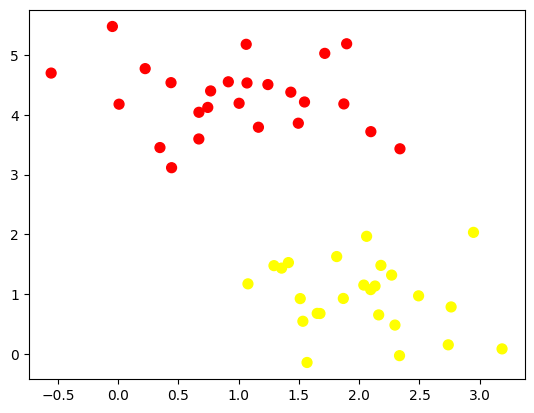

In [5]:
# Membuat Data Dummy

from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

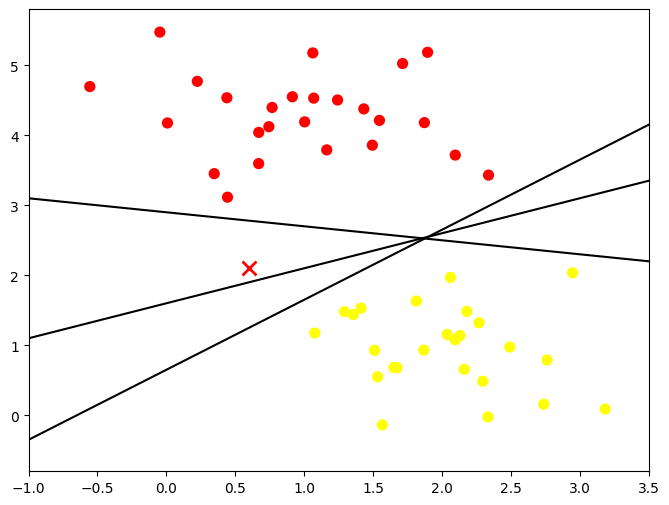

In [8]:
# Buat Ilustrasi Garis Pemisah

# Menggabungkan titik data dummy dan garis pemisah dalam satu gambar
plt.figure(figsize=(8, 6))

# Titik-titik data dummy (merah dan kuning)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menambahkan titik data baru berwarna merah bertanda 'x'
xfit = np.linspace(-1, 3.5)
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# Menambahkan tiga garis pemisah
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# Batas sumbu X dan Y
plt.xlim(-1, 3.5)
plt.ylim(-0.8, 5.8)

plt.show()

(-1.0, 3.5)

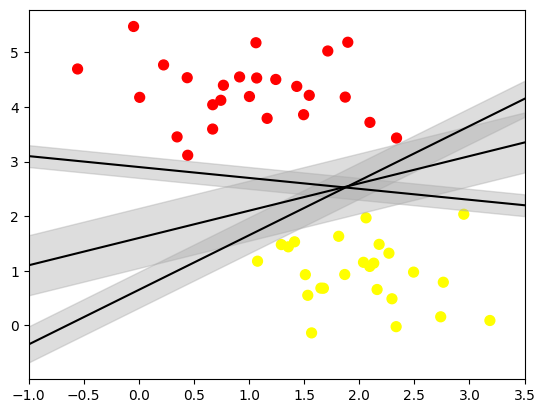

In [9]:
# Ilustrasi Margin

xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
  yfit = m * xfit + b
  plt.plot(xfit, yfit, '-k')
  plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none', color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

In [10]:
# Fitting model

from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [14]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

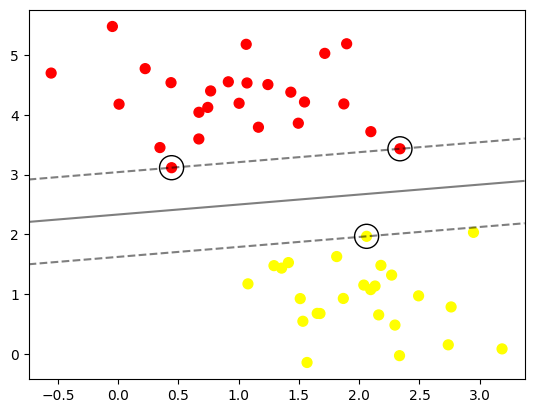

In [15]:
# Melakukan plotting dengan fungsi yang telah dibuat

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

In [16]:
# Memanggil support_vectors_ untuk mengetahui data yang masuk ke dalam support vector

model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

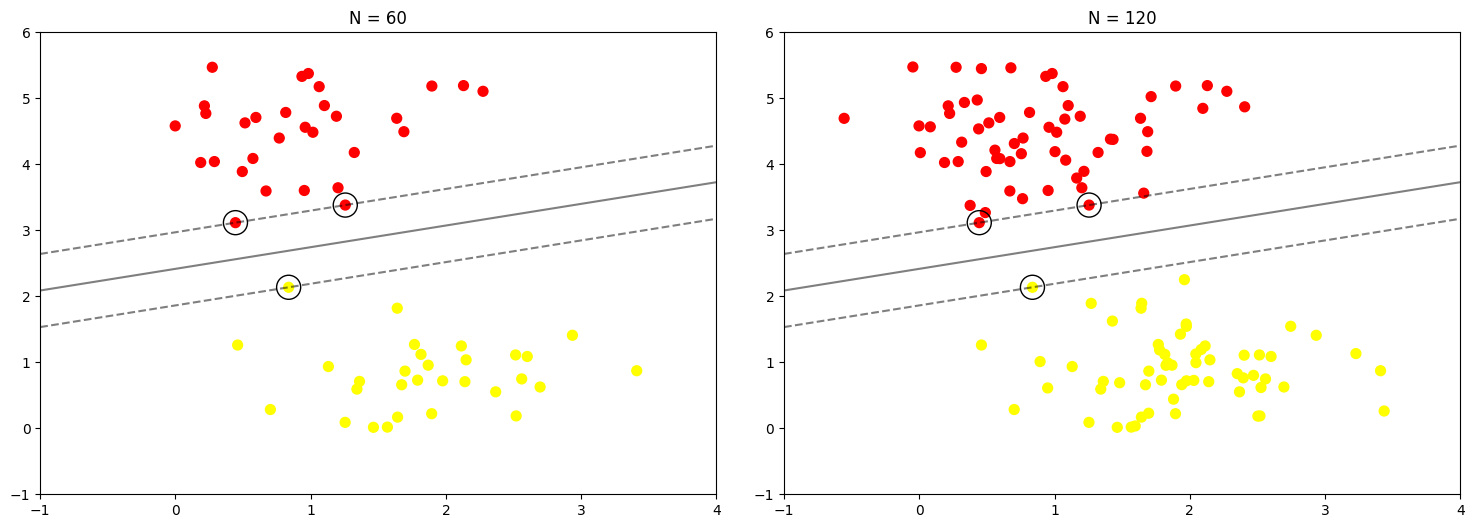

In [18]:
# 60 dan 120 data awal digunakan sebagai contoh dalam bentuk perbandingan.

def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

In [22]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

In [21]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 15.8 MB/s  0:00:00


# **PRAKTIKUM 2**

In [24]:
# Ilutrasi Data Non-Linier

# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

In [26]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

	  # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

	  # plot batas dan margin
    ax.contour(X, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

	  # plot support vectors
    if plot_support:
	      ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

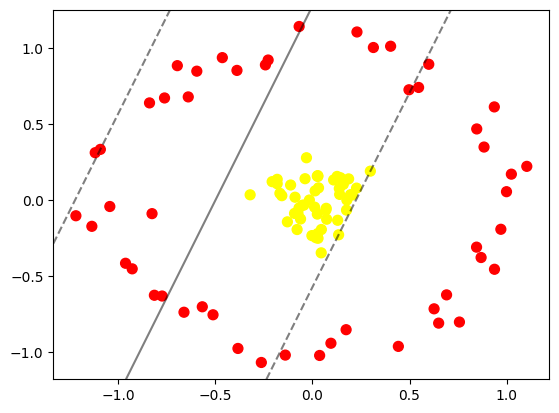

In [27]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 1.75715610e-01, -6.65379657e-02],
       [ 3.14318498e-02,  7.97942377e-02],
       [-1.28859171e-01, -1.43625669e-01],
       [-8.25837661e-01, -8.97857816e-02],
       [-1.57085386e-02, -3.27999642e-04],
       [-9.28005999e-01, -4.52755154e-01],
       [ 1.13201821e-02, -4.70548229e-02],
       [ 5.46764852e-01,  7.40024514e-01],
       [ 4.53500111e-02, -3.47552216e-01],
       [ 6.94906201e-02, -6.55716544e-02],
       [ 2.29367175e-01,  1.10483516e+00],
       [-9.62254962e-01, -4.16152336e-01],
       [ 1.40312640e-01,  3.66809844e-02],
       [-6.89256936e-02, -5.28133348e-02],
       [ 3.13965912e-01,  1.00270841e+00],
       [ 1.02445480e+00,  1.69794191e-01],
       [ 1.44302274e-01,  1.46381078e-01],
       [ 1.73583313e-01, -8.52947644e-01],
       [ 7.57064587e-01, -8.02603967e-01],
       [-2.27960373e-01,  9.20373308e-01],
       [-8.13736123e-01, -6.26553418e-01],
       [-2.70022569e-03, -2.34214324e-01],
       [ 4.60199725e-02, -1.94163055e-01],
       [ 1.38503676e-01,  7.55704077e-02],
       [-5.67067014e-01, -7.02337114e-01],
       [-9.20175671e-02, -8.82144565e-02],
       [ 2.77352189e-02,  1.60075474e-01],
       [ 2.70105260e-02, -2.21216279e-01],
       [ 1.39384959e-02,  6.00743539e-02],
       [-4.63916452e-01,  9.36127835e-01],
       [-3.05928085e-02,  2.77733118e-01],
       [ 2.27263485e-01,  7.79729185e-02],
       [ 1.86479606e-01,  1.38836370e-01],
       [ 9.99450888e-01,  5.45788705e-02],
       [-1.81344740e-01,  1.35808373e-01],
       [ 4.97297142e-01,  7.24750301e-01],
       [-5.18571383e-02, -3.45279851e-02],
       [-5.11790942e-01, -7.54878802e-01],
       [-1.81422299e-01,  1.06867921e-01],
       [-2.07335166e-01,  1.20615236e-01],
       [-4.44035704e-02, -3.39279150e-02],
       [-6.39351528e-01,  6.77840751e-01],
       [ 2.98323248e-01,  1.89664121e-01],
       [ 5.99172483e-01,  8.92464741e-01],
       [ 2.54004933e-02, -9.27837008e-02],
       [ 1.27128054e-01,  1.54914802e-01],
       [-6.83155823e-02,  1.14099186e+00],
       [ 8.83754830e-01,  3.48101476e-01],
       [-6.95643812e-01,  8.83363988e-01],
       [ 4.02711966e-01,  1.01108777e+00],
       [-6.61337727e-01, -7.38159543e-01],
       [ 2.04851070e-01,  3.28947138e-02],
       [-2.63024192e-01, -1.06854866e+00],
       [ 8.68653478e-01, -3.78305409e-01],
       [-1.13572504e+00, -1.73195678e-01],
       [-7.74111373e-01, -6.31570766e-01],
       [-8.38811073e-01,  6.38408511e-01],
       [-1.12268197e-01,  9.84367646e-02],
       [-1.67355813e-01,  4.37612357e-02],
       [ 9.70367365e-01, -1.92608744e-01],
       [-5.95246153e-01,  8.47039208e-01],
       [ 6.26573284e-01, -7.15685194e-01],
       [-1.09195184e+00,  3.32800093e-01],
       [ 1.81151714e-02, -2.47840368e-01],
       [-1.04322210e+00, -4.28336455e-02],
       [-1.11838354e+00,  3.11085880e-01],
       [ 7.10639873e-02, -5.48167427e-02],
       [-3.88534807e-01,  8.52154399e-01],
       [-1.39603101e-01, -1.01995890e+00],
       [ 1.58951104e-01,  1.02869934e-01],
       [ 8.46210171e-01,  4.67194076e-01],
       [-7.88510730e-02, -1.94255129e-01],
       [-1.57555318e-01,  2.82072477e-02],
       [-3.83421984e-01, -9.76296761e-01],
       [-3.20664631e-01,  3.40288444e-02],
       [-7.61476644e-01,  6.70905278e-01],
       [ 1.77387176e-01, -2.52066858e-05],
       [ 1.09190669e-01,  1.31783401e-01],
       [ 8.45229693e-01, -3.10139700e-01],
       [ 1.96204258e-01,  3.47337425e-02],
       [-1.21792121e+00, -1.03697943e-01],
       [ 1.10397639e+00,  2.21165922e-01],
       [ 9.36691140e-01,  6.12033375e-01],
       [ 1.29955448e-01, -1.33376243e-01],
       [ 3.71941687e-02, -1.02243458e+00],
       [ 4.42530908e-01, -9.62721608e-01],
       [ 6.90851275e-01, -6.23918784e-01],
       [ 2.51280136e-02,  1.56986708e-01],
       [-3.78849801e-02,  1.39928399e-01],
       [-2.41962303e-01,  8.88461054e-01],
       [ 6.50104311e-01, -8.09776596e-01],
       [ 2.88806500e-02, -2.51772604e-01

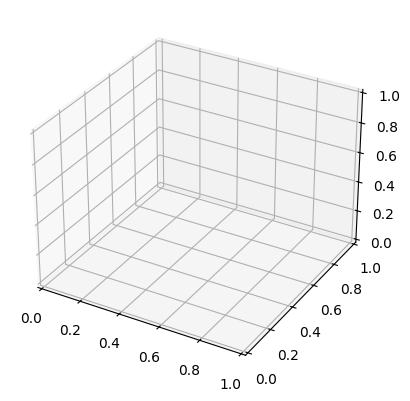

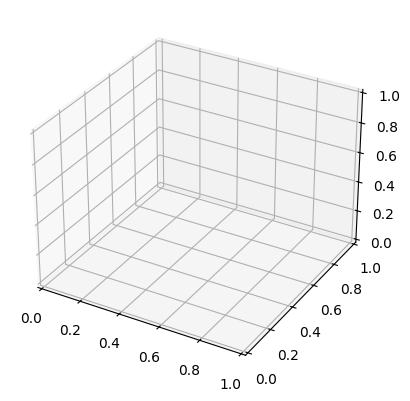

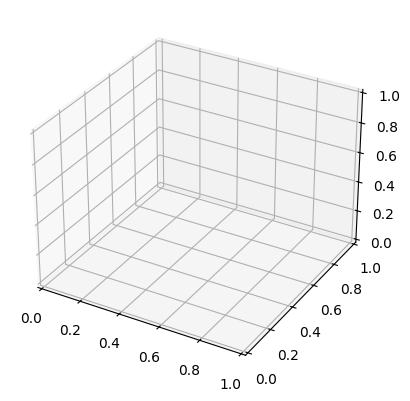

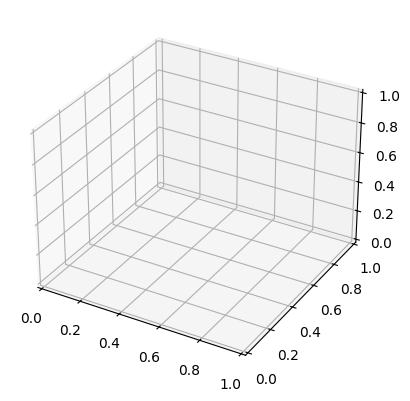

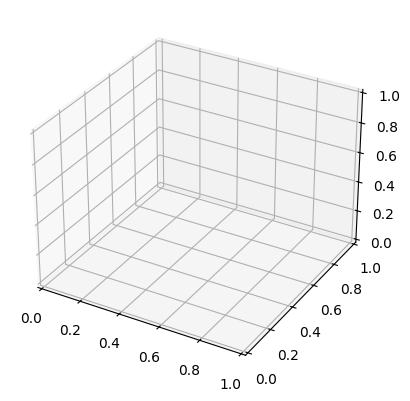

In [31]:
# Plot visualisasi diubah menjadi model 3D

from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

def plot_3D(elev=30, azim=30, X=X, y=y):
  ax = plt.subplot(projection='3d')
  ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
  ax.view_init(elev=elev, azim=azim)
  ax.set_xlabel('x')
  ax.set_ylabel('y')
  ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20 , 10], azip=(-180, 180), X=fixed(X), y=fixed(y))

In [32]:
# Fitting Model

clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

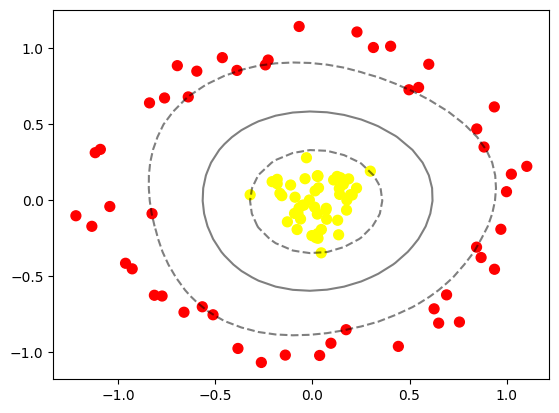

In [33]:
# Plot hasil decision boundaries dari kernel RBF

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=300, lw=1, facecolors='none')

# **PRAKTIKUM 3**

In [34]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [36]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

	  # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

	  # plot batas dan margin
    ax.contour(X, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

	  # plot support vectors
    if plot_support:
	      ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

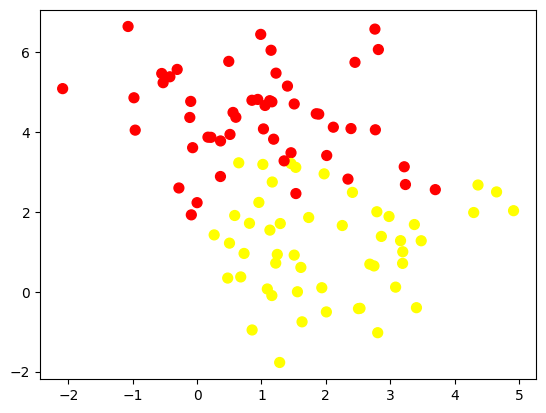

In [37]:
# Buat Data Dummy

X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

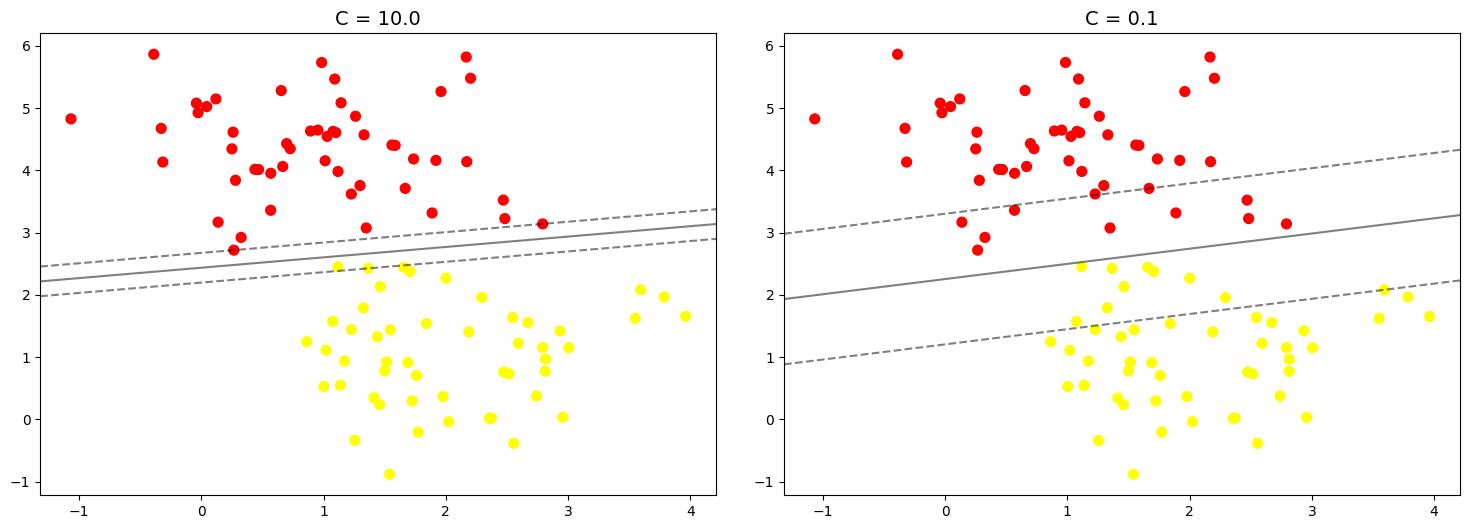

In [39]:
# Analisis Dampak Tunning

X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# **PRAKTIKUM 4**

In [40]:
# Unduh Dataset

from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


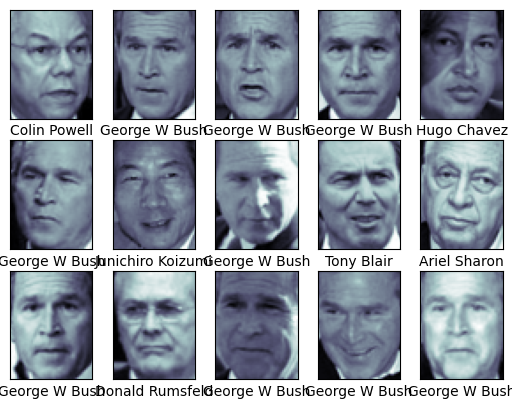

In [41]:
# Inspeksi Citra Wajah

# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[], xlabel=faces.target_names[faces.target[i]])

In [42]:
# Pra Pengolahan Data

from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

In [43]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

In [44]:
# Pembuatan Model + Tunning

from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50], 'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 1min 45s, sys: 107 ms, total: 1min 45s
Wall time: 1min 19s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [45]:
# Menggunakan model tsb untuk proses prediksi

model = grid.best_estimator_
yfit = model.predict(Xtest)

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

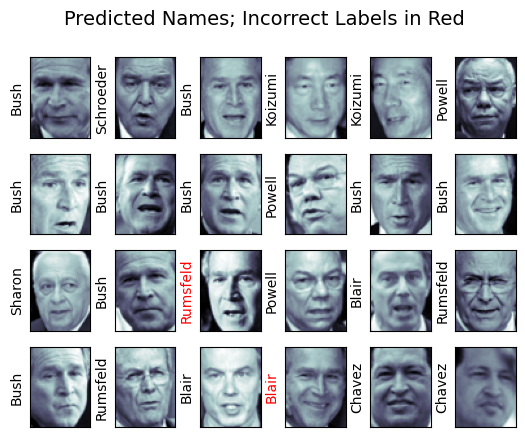

In [46]:
# Cek Hasil Prediksi

# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1], color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

In [47]:
# Cek Performansi

from sklearn.metrics import classification_report
print(classification_report(ytest, yfit, target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

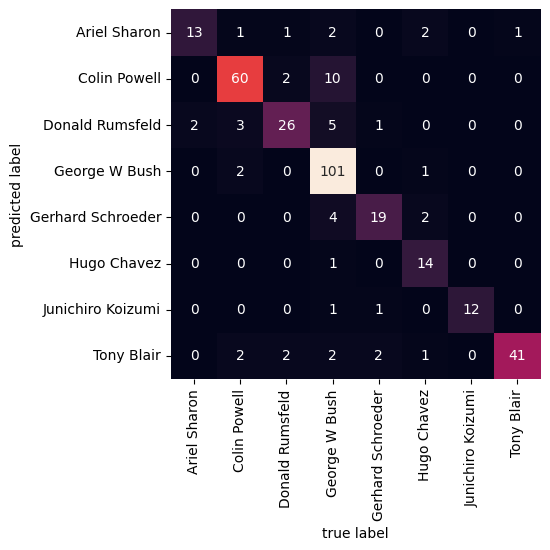

In [48]:
# bentuk confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False, xticklabels=faces.target_names, yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')

# **PRAKTIKUM 5**

In [19]:
# Upload file
from google.colab import files
uploaded = files.upload()

Saving images.zip to images (2).zip


In [20]:
# Extract ke folder sementara
!unzip -q -o images.zip -d /content/_extract

In [21]:
import shutil
from pathlib import Path

# Cari folder yang benar-benar punya subfolder day & night
src = None
for p in Path('/content/_extract').rglob('training'):
    if p.is_dir() and (p / 'day').is_dir() and (p / 'night').is_dir():
        src = p.parent
        break

assert src is not None, 'Folder training/day & night tidak ditemukan. Cek isi zip.'
print(f'Dataset ditemukan di: {src}')

dst = Path('/content/images')
if dst.exists():
    shutil.rmtree(dst)
shutil.copytree(src, dst)

# Verifikasi jumlah gambar (harus 120/120 dan 80/80)
for split in ['training', 'test']:
    for lab in ['day', 'night']:
        n = len(list((dst / split / lab).glob('*.jpg')))
        print(f'{split}/{lab}: {n} gambar')

Dataset ditemukan di: /content/_extract/images
training/day: 120 gambar
training/night: 120 gambar
test/day: 80 gambar
test/night: 80 gambar


In [22]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [23]:
# Image directories
train_dir = "images/training/"
test_dir = "images/test/"

In [12]:
# fungsi untuk membuat daftar seluruh path dari gambar

def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = sorted(p.glob('*'))

    img_list = []

    for dir in dirs:
        if not dir.is_dir():          # lewati file, ambil folder saja
            continue

        # PERBAIKAN: pakai dir.name, bukan str(dir).split('/')[-1]
        # supaya label tetap benar di Linux (Colab) maupun Windows
        label = dir.name

        for file in sorted(dir.glob('*.jpg')):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

In [14]:
# Load training data
train_img = load_dataset(train_dir)

print(f'Total gambar training: {len(train_img)}')

# Distribusi label (harus day: 120, night: 120)
from collections import Counter
print(Counter(label for _, label in train_img))

Total gambar training: 240
Counter({'day': 120, 'night': 120})


In [24]:
# Melakukan pengecekan pada salah satu data pada list
# List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar

train_img[0]

(array([[[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [176, 209, 228],
         [177, 210, 229],
         [177, 210, 229]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [180, 213, 232],
         [180, 213, 232],
         [180, 213, 232]],
 
        [[158, 194, 218],
         [158, 194, 218],
         [158, 194, 218],
         ...,
         [177, 210, 229],
         [177, 210, 229],
         [177, 210, 229]],
 
        ...,
 
        [[ 35,  40,  43],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 65,  73,  75],
         [ 65,  73,  75],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
         [ 68,  76,  78],
         [ 65,  73,  75]],
 
        [[ 36,  41,  44],
         [ 38,  43,  46],
         [ 39,  44,  47],
         ...,
         [ 68,  76,  78],
  

In [25]:
# Cek data pertama: harus tuple (array gambar, label string)
print(f'Tipe data : {type(train_img[0])}')
print(f'Shape     : {train_img[0][0].shape}')
print(f'Label     : {train_img[0][1]}')

Tipe data : <class 'tuple'>
Shape     : (458, 800, 3)
Label     : day


In [26]:
# Cek ukuran gambar secara acak

pick_random = np.random.randint(0, len(train_img))

# CCek ukuran img
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)


Image 168
(555, 800, 3)


In [27]:
# Fungsi untuk membantu memvisualkan gambar

def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    # PERBAIKAN: label bisa string ('day'/'night') atau angka (1/0)
    if isinstance(label, str):
        label_str = label
    else:
        label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    plt.axis('off')
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label_str}')

Shape	: (469, 640, 3)
Label	: night


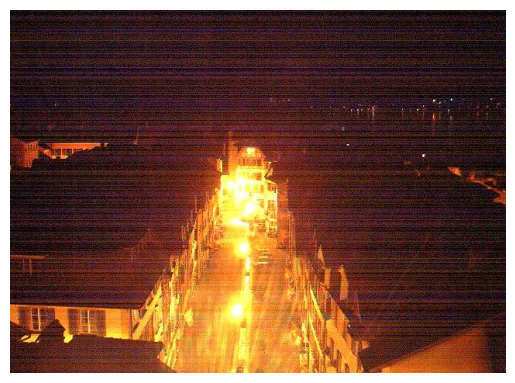

In [28]:
# Visualisasi gambar secara acak

random_img_viz(train_img)

In [29]:
# Pra Pengolahan Data
# Fungsi untuk menstandarkan ukuran gambar

def standarized_input(image):
    # ubah ukuran ke w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [30]:
# Fungsi untuk kebutuhan encoding label

def label_encoder(label):
    # day sebagai 1; night sebagai 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [31]:
# Fungsi untuk melakukan kedua hal tersebut secara sekaligus untuk semua gambar dalam list

def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarisasi gambar
        std_img = standarized_input(image)

        # Buat label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [32]:
# Pra pengolahan data pada data training

train_std_img_list = preprocess(train_img)

In [33]:
# Pengecekan ukuran gambar secara acak

pick_random = np.random.randint(0, len(train_std_img_list))

# Cek ukuran img
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 211
(600, 1100, 3)


In [34]:
# Fungsi untuk membantu memvisualkan gambar

def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (469, 640, 3)
Label	: night


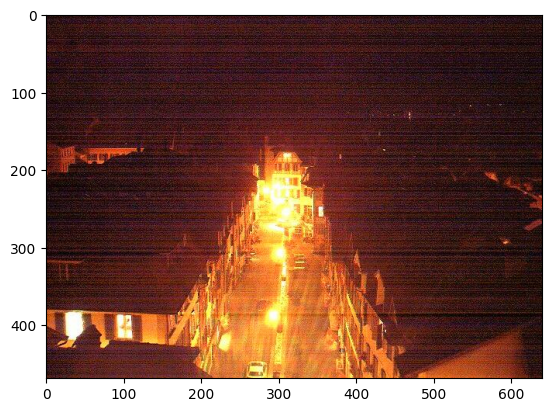

In [35]:
# Visualisasi gambar secara acak

random_img_viz(train_img)

In [36]:
# fungsi berikut untuk mendapatkan nilai rata-rata tingkat kecerahan

# Dapatkan fitur berdasarkan kecerahan rata-rata menggunakan ruang warna HSV
def avg_brightness(image):
    # Konversi gambar ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Hitung rata-rata kecerahan
    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 22
Avg Brightness: 109.0393


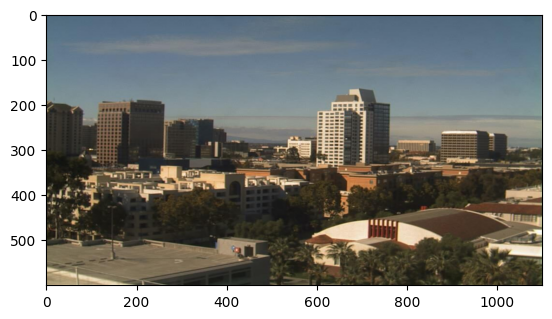

In [37]:
# Lakukan pengecekan pada gambar secara acak

# Cek gambar acak
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')
plt.imshow(feature_img)

In [38]:
# Klasifikasi dengan Metode Threshold

def predict_label(img, threshold):
    # Kecerahan rata-rata komputer
    avg = avg_brightness(img)
    pred = 0

    # Memprediksi label berdasarkan ambang batas yang ditentukan pengguna
    if avg > threshold:
        pred = 1

    return pred

Image 176
Actual label   : 0
Predicted label: 0


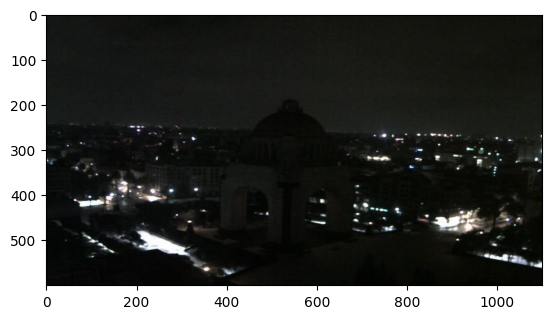

In [42]:
# Pengecekan prediksi secara acak pada data training

# Uji klasifikasi pada data pelatihan
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Evaluasi
print(f'Image {rand_img}')
print(f'Actual label   : {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

In [43]:
# Evaluasi manual

def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Dapatkan data referensi / label yang benar
        img   = file[0]
        label = file[1]

        # Dapatkan prediksi
        pred_label = predict_label(img, threshold)

        # Bandingkan data sebenarnya dan prediksi
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy  = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [44]:
# Evaluasi pada data training dengan threshold 120
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [45]:
# Evaluasi pada data testing

# Memuat data testing
test_img = load_dataset(test_dir)

# Preprocess
test_std_img_list = preprocess(test_img)

# Prediksi
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


In [46]:
# Buat fungsi untuk mengekstrak fitur dari setiap gambar dan menyimpannya dalam bentuk data tabel
# Disimpan dalam dataframe Pandas

def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg   = avg_brightness(img[0]) # Dapatkan rata rata kecerahan dari gambar
        img_label = img[1] # Dapatkan label pada gambar

        avg_list.append(img_avg)
        labels.append(img_label)

    # Menumpuk data secara kolom
    data = np.column_stack((avg_list, labels))

    # Buat sebuah dataframe Pandas
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [47]:
# Cek hasilnya pada data training
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1.0
1,192.907867,1.0
2,132.133823,1.0
3,199.749191,1.0
4,109.947203,1.0


In [48]:
# Melakukan hal yang sama pada data testing
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1.0
1,157.826662,1.0
2,201.607444,1.0
3,191.237441,1.0
4,188.119652,1.0


In [49]:
# Buat Model SVM

# import library
from sklearn.svm import SVC

# Split data dan label
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]

X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

SVC()

In [50]:
# evaluasi pada data training dan testing dengan bantuan library scikit-learn

from sklearn.metrics import accuracy_score

# Prediksi pada data training
y_train_pred = model.predict(X_train)

# Dapatkan akurasi pada data training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi pada data testing
y_test_pred = model.predict(X_test)

# Dapatkan akurasi pada data testing
acc_test = accuracy_score(y_test, y_test_pred)

# Hasil evaluasi
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test : {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test : 0.9


# **TUGAS PRAKTIKUM**

1. Buatlah model SVM dengan menggunakan data `voice.csv` dengan ketentuan:
   
   a. Split data dengan rasio 70:30 dan 80:20 untuk setiap model yang akan dibangun.
      
      i. Gunakan model dengan kernel linier.
      
      ii. Gunakan model dengan kernel polynomial.
      
      iii. Gunakan model dengan kernel RBF.
   
   b. Tabulasikan performansi setiap split dan kernel berdasarkan metrik akurasi.


### Jawaban No. 1

In [51]:
# Load data

import pandas as pd

df_voice = pd.read_csv('voice (1).csv')

print(f'Shape: {df_voice.shape}')
print(f'Jumlah fitur: {df_voice.shape[1] - 1}')
print()
print('Distribusi label:')
print(df_voice['label'].value_counts())
display(df_voice.head())

Shape: (3168, 21)
Jumlah fitur: 20

Distribusi label:
label
male      1584
female    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [52]:
# Menyiapkan fitur, label, dan fungsi evaluasi

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

X = df_voice.drop(columns=['label']).values
y = LabelEncoder().fit_transform(df_voice['label'])   # female = 0, male = 1

print(f'X: {X.shape} | y: {y.shape}')
print(f'Kelas: {np.unique(y)} (0 = female, 1 = male)')

X: (3168, 20) | y: (3168,)
Kelas: [0 1] (0 = female, 1 = male)


In [53]:
# Latih 6 model (2 rasio split & 3 kernel)

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

SPLITS  = {'70:30': 0.30, '80:20': 0.20}
KERNELS = {
    'Linear'    : {'kernel': 'linear'},
    'Polynomial': {'kernel': 'poly', 'degree': 3},
    'RBF'       : {'kernel': 'rbf'},
}

results = []
trained = {}

for split_name, test_size in SPLITS.items():
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )

    scaler  = StandardScaler()
    X_tr_s  = scaler.fit_transform(X_tr)    # fit hanya pada train
    X_te_s  = scaler.transform(X_te)

    for kernel_name, params in KERNELS.items():
        t0 = time.time()

        clf = SVC(**params)
        clf.fit(X_tr_s, y_tr)

        y_pred_tr = clf.predict(X_tr_s)
        y_pred_te = clf.predict(X_te_s)

        results.append({
            'SPLIT'      : split_name,
            'KERNEL'     : kernel_name,
            'N_TRAIN'    : len(y_tr),
            'N_TEST'     : len(y_te),
            'ACC_TRAIN'  : round(accuracy_score(y_tr, y_pred_tr), 4),
            'ACC_TEST'   : round(accuracy_score(y_te, y_pred_te), 4),
            'PRECISION'  : round(precision_score(y_te, y_pred_te), 4),
            'RECALL'     : round(recall_score(y_te, y_pred_te), 4),
            'F1_SCORE'   : round(f1_score(y_te, y_pred_te), 4),
            'WAKTU (s)'  : round(time.time() - t0, 2),
        })

        trained[(split_name, kernel_name)] = (clf, X_te_s, y_te, y_pred_te)

df_result = pd.DataFrame(results)
print('Selesai. 6 model telah dilatih.')

Selesai. 6 model telah dilatih.


In [54]:
# Tabulasi performansi
print('=== Tabel Lengkap Performansi ===')
display(df_result)

print('\n=== Akurasi Testing per Split dan Kernel ===')
pivot_acc = df_result.pivot(index='KERNEL', columns='SPLIT', values='ACC_TEST')
display(pivot_acc)

print('\n=== F1-Score per Split dan Kernel ===')
pivot_f1 = df_result.pivot(index='KERNEL', columns='SPLIT', values='F1_SCORE')
display(pivot_f1)

best = df_result.loc[df_result['ACC_TEST'].idxmax()]
print(f"\nModel terbaik: split {best['SPLIT']} + kernel {best['KERNEL']} "
      f"(akurasi test = {best['ACC_TEST']})")

=== Tabel Lengkap Performansi ===


,SPLIT,KERNEL,N_TRAIN,N_TEST,ACC_TRAIN,ACC_TEST,PRECISION,RECALL,F1_SCORE,WAKTU (s)
0,70:30,Linear,2217,951,0.9720,0.9790,0.9730,0.9853,0.9791,0.11
1,70:30,Polynomial,2217,951,0.9666,0.9600,0.9344,0.9895,0.9611,0.22
2,70:30,RBF,2217,951,0.9838,0.9832,0.9811,0.9853,0.9832,0.20
3,80:20,Linear,2534,634,0.9767,0.9748,0.9659,0.9842,0.9750,0.13
4,80:20,Polynomial,2534,634,0.9680,0.9558,0.9263,0.9905,0.9573,0.29
5,80:20,RBF,2534,634,0.9838,0.9826,0.9781,0.9874,0.9827,0.22



=== Akurasi Testing per Split dan Kernel ===


SPLIT,70:30,80:20
KERNEL,,
Linear,0.9790,0.9748
Polynomial,0.9600,0.9558
RBF,0.9832,0.9826



=== F1-Score per Split dan Kernel ===


SPLIT,70:30,80:20
KERNEL,,
Linear,0.9791,0.9750
Polynomial,0.9611,0.9573
RBF,0.9832,0.9827



Model terbaik: split 70:30 + kernel RBF (akurasi test = 0.9832)


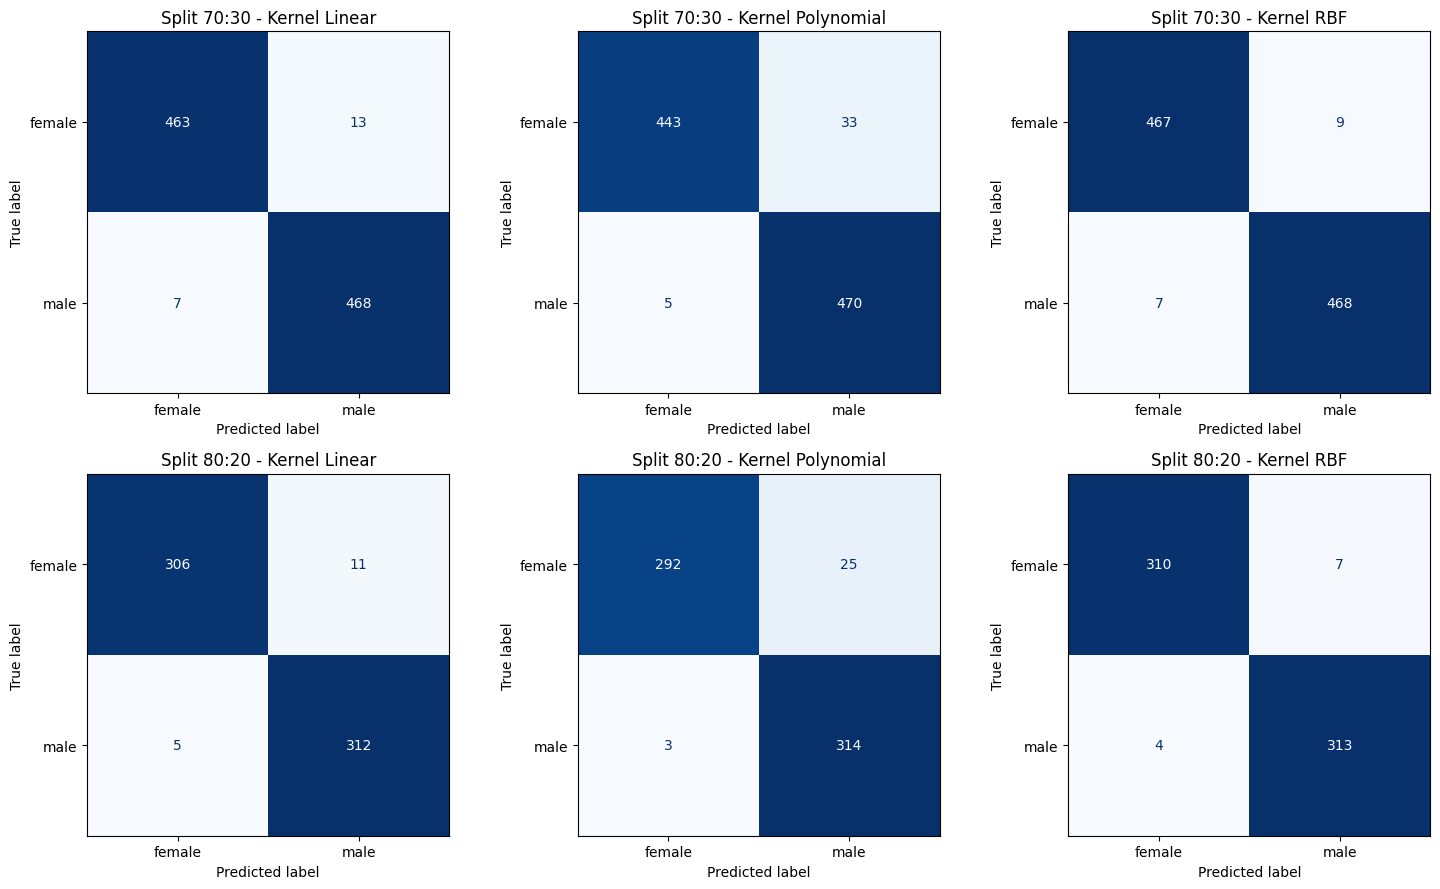

In [55]:
# Confusion matrix tiap model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (key, (clf, Xte, yte, ypred)) in zip(axes.flat, trained.items()):
    cm = confusion_matrix(yte, ypred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['female', 'male']).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(f'Split {key[0]} - Kernel {key[1]}')

plt.tight_layout()
plt.show()

In [56]:
# Hyperparameter tuning (penguat analisis)

# Membandingkan performansi model *default* dengan model setelah `GridSearchCV`.
from sklearn.model_selection import GridSearchCV

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10, 100]},
    {'kernel': ['rbf'],    'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.01, 0.1]},
    {'kernel': ['poly'],   'C': [0.1, 1, 10], 'degree': [2, 3, 4], 'gamma': ['scale']},
]

grid_voice = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_voice.fit(X_tr_s, y_tr)

print(f'Best params   : {grid_voice.best_params_}')
print(f'Best CV score : {grid_voice.best_score_:.4f}')
print(f'Acc train     : {accuracy_score(y_tr, grid_voice.predict(X_tr_s)):.4f}')
print(f'Acc test      : {accuracy_score(y_te, grid_voice.predict(X_te_s)):.4f}')

Best params   : {'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}
Best CV score : 0.9815
Acc train     : 1.0000
Acc test      : 0.9858


2. Gunakan data pada praktikum 5 untuk membuat model klasifikasi siang dan malam menggunakan SVM dengan kernel RBF menggunakan fitur histogram. Gunakan rasio 80:20. Anda dapat bereksperimen dengan hyperparameter tuning dari kernel RBF. Catat performansi akurasinya!

### Jawaban No. 2

In [57]:
# Fungsi ekstraksi fitur histogram HSV

def hsv_histogram_feature(image, bins=(32, 32, 32)):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    ranges = [(0, 180), (0, 256), (0, 256)]   # rentang OpenCV: H 0-180, S/V 0-256

    feats = []
    for ch in range(3):
        hist = cv2.calcHist([img_hsv], [ch], None, [bins[ch]], list(ranges[ch]))
        hist = cv2.normalize(hist, hist).flatten()   # normalisasi L2
        feats.append(hist)

    return np.concatenate(feats)

In [59]:
def extract_hist_dataset(img_list):
    features = []
    labels   = []

    for img, label in img_list:
        features.append(hsv_histogram_feature(img))
        labels.append(label)

    return np.array(features), np.array(labels)


X_hist_train, y_hist_train = extract_hist_dataset(train_std_img_list)
X_hist_test,  y_hist_test  = extract_hist_dataset(test_std_img_list)

print(f'X_train: {X_hist_train.shape} | y_train: {y_hist_train.shape}')
print(f'X_test : {X_hist_test.shape}  | y_test : {y_hist_test.shape}')

X_train: (240, 96) | y_train: (240,)
X_test : (160, 96)  | y_test : (160,)


In [60]:
# Seluruh 400 gambar (240 train + 160 test asli) digabung lalu di-split ulang 80:20 secara stratified.

from sklearn.model_selection import train_test_split

X_all = np.vstack([X_hist_train, X_hist_test])
y_all = np.concatenate([y_hist_train, y_hist_test])

X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

print(f'Total data : {X_all.shape[0]} gambar')
print(f'Train (80%): {X_tr.shape[0]} gambar')
print(f'Test  (20%): {X_te.shape[0]} gambar')
print(f'Distribusi train: night={int((y_tr==0).sum())}, day={int((y_tr==1).sum())}')
print(f'Distribusi test : night={int((y_te==0).sum())}, day={int((y_te==1).sum())}')

Total data : 400 gambar
Train (80%): 320 gambar
Test  (20%): 80 gambar
Distribusi train: night=160, day=160
Distribusi test : night=40, day=40


In [61]:
# Model SVM RBF baseline

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_hist = SVC(kernel='rbf')
svm_hist.fit(X_tr, y_tr)

hist_acc_train_base = accuracy_score(y_tr, svm_hist.predict(X_tr))
hist_acc_test_base  = accuracy_score(y_te, svm_hist.predict(X_te))

print('SVM RBF + Histogram HSV (parameter default)')
print(f'Accuracy train: {hist_acc_train_base:.4f}')
print(f'Accuracy test : {hist_acc_test_base:.4f}')
print()
print(classification_report(y_te, svm_hist.predict(X_te), target_names=['night', 'day']))

SVM RBF + Histogram HSV (parameter default)
Accuracy train: 1.0000
Accuracy test : 0.9875

              precision    recall  f1-score   support

       night       1.00      0.97      0.99        40
         day       0.98      1.00      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



In [62]:
# Hyperparameter tuning kernel RBF

from sklearn.model_selection import GridSearchCV

param_grid = {
    'C'    : [0.1, 1, 10, 100, 1000],
    'gamma': ['scale', 'auto', 1e-4, 1e-3, 1e-2, 1e-1],
}

grid_hist = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_hist.fit(X_tr, y_tr)

print(f'Best params   : {grid_hist.best_params_}')
print(f'Best CV score : {grid_hist.best_score_:.4f}')

best_hist = grid_hist.best_estimator_
hist_acc_train_tuned = accuracy_score(y_tr, best_hist.predict(X_tr))
hist_acc_test_tuned  = accuracy_score(y_te, best_hist.predict(X_te))

print(f'Acc train     : {hist_acc_train_tuned:.4f}')
print(f'Acc test      : {hist_acc_test_tuned:.4f}')

Best params   : {'C': 1, 'gamma': 'scale'}
Best CV score : 1.0000
Acc train     : 1.0000
Acc test      : 0.9875


In [63]:
# Visualisasi sensitivitas model terhadap hyperparameter

cvres = pd.DataFrame(grid_hist.cv_results_)

pivot_cv = cvres.pivot_table(
    index='param_C', columns='param_gamma', values='mean_test_score'
)
pivot_cv.index.name  = 'C'
pivot_cv.columns.name = 'gamma'
print('Rata-rata akurasi cross-validation (5-fold):')
display(pivot_cv.round(4))

Rata-rata akurasi cross-validation (5-fold):


gamma,0.0001,0.001,0.01,0.1,auto,scale
C,,,,,,
0.1,0.8906,0.8906,0.8906,0.8938,0.8906,0.9906
1.0,0.8906,0.8906,0.8906,0.9938,0.8906,1.0000
10.0,0.8906,0.8906,0.9938,1.0000,0.9938,1.0000
100.0,0.8906,0.9938,1.0000,1.0000,1.0000,1.0000
1000.0,0.9938,1.0000,1.0000,1.0000,1.0000,1.0000


In [65]:
# Perbandingan fitur: Average Brightness vs Histogram HSV

# Melatih model avg brightness dengan split 80:20 yang identik, agar perbandingan adil
bright_all = np.concatenate([
    train_avg_img['AVG_BRIGHT'].values,
    test_avg_img['AVG_BRIGHT'].values
]).reshape(-1, 1)

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    bright_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Baseline: parameter default
svm_bright_base = SVC(kernel='rbf')
svm_bright_base.fit(Xb_tr, yb_tr)
bright_acc_train_base = accuracy_score(yb_tr, svm_bright_base.predict(Xb_tr))
bright_acc_test_base  = accuracy_score(yb_te, svm_bright_base.predict(Xb_te))

# Tuned: GridSearchCV
grid_bright = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_bright.fit(Xb_tr, yb_tr)
best_bright = grid_bright.best_estimator_
bright_acc_train_tuned = accuracy_score(yb_tr, best_bright.predict(Xb_tr))
bright_acc_test_tuned  = accuracy_score(yb_te, best_bright.predict(Xb_te))

print(f'Best params avg brightness: {grid_bright.best_params_}')
print(f'Acc test avg brightness (tuned): {bright_acc_test_tuned:.4f}')

Best params avg brightness: {'C': 1000, 'gamma': 0.1}
Acc test avg brightness (tuned): 0.8875


In [66]:
comparison = pd.DataFrame([
    ['Average Brightness (1D)', 'RBF default', bright_acc_train_base,  bright_acc_test_base],
    ['Average Brightness (1D)', f"RBF tuned {grid_bright.best_params_}",
                                              bright_acc_train_tuned, bright_acc_test_tuned],
    ['Histogram HSV (96D)',     'RBF default', hist_acc_train_base,    hist_acc_test_base],
    ['Histogram HSV (96D)',     f"RBF tuned {grid_hist.best_params_}",
                                              hist_acc_train_tuned,   hist_acc_test_tuned],
], columns=['FITUR', 'MODEL', 'ACC_TRAIN', 'ACC_TEST'])

comparison['ACC_TRAIN'] = comparison['ACC_TRAIN'].round(4)
comparison['ACC_TEST']  = comparison['ACC_TEST'].round(4)

print('=== Perbandingan Performansi (split 80:20) ===')
display(comparison)

=== Perbandingan Performansi (split 80:20) ===


,FITUR,MODEL,ACC_TRAIN,ACC_TEST
0,Average Brightness (1D),RBF default,0.8750,0.8750
1,Average Brightness (1D),"RBF tuned {'C': 1000, 'gamma': 0.1}",0.9406,0.8875
2,Histogram HSV (96D),RBF default,1.0000,0.9875
3,Histogram HSV (96D),"RBF tuned {'C': 1, 'gamma': 'scale'}",1.0000,0.9875


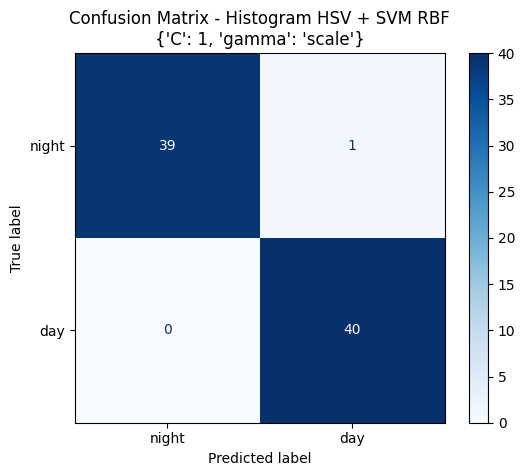

[[39  1]
 [ 0 40]]
TN=39  FP=1
FN=0  TP=40


In [67]:
# Confusion matrix model terbaik

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_hist = confusion_matrix(y_te, best_hist.predict(X_te), labels=[0, 1])
ConfusionMatrixDisplay(cm_hist, display_labels=['night', 'day']).plot(cmap='Blues')
plt.title(f'Confusion Matrix - Histogram HSV + SVM RBF\n{grid_hist.best_params_}')
plt.show()

print(cm_hist)
print(f'TN={cm_hist[0,0]}  FP={cm_hist[0,1]}')
print(f'FN={cm_hist[1,0]}  TP={cm_hist[1,1]}')

## Catatan Akhir

**Penyebab hasil tidak sesuai jobsheet sebelumnya:**

| Gejala | Penyebab | Perbaikan |
|---|---|---|
| `Label: cats` | Folder `images/training` berisi dataset cats/dogs | Bagian A notebook ini |
| Shape `(100, 100, 3)` | Gambar cats/dogs berukuran 100x100 | Bagian A notebook ini |
| Akurasi tidak mendekati 0.84 | Semua label ter-encode jadi `0` (night) | Bagian A notebook ini |
| `label_str` tidak tampil | Variabel dihitung tapi tidak dipakai di `print` | Fungsi `random_img_viz` diperbaiki |
| `NameError: r` (Praktikum 2) | Variabel `r` tidak didefinisikan | Bagian G |

**Nilai acuan yang sudah diverifikasi pada dataset asli:**

| Model | Acc Train | Acc Test |
|---|---|---|
| Threshold 120 | 0.8417 | 0.8688 |
| Threshold 103 (optimal) | 0.9125 | 0.9250 |
| SVM RBF avg brightness | ~0.8583 | ~0.9000 |